In [1]:
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
TABLES = ROOT / "results" / "tables"
FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

COLORS = {"logistic": "#2a78d6", "lightgbm": "#eb6834", "glmer": "#1baf7a"}
NAMES = {"logistic": "Logistic regression", "lightgbm": "LightGBM",
         "glmer": "Multilevel model"}
plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e5e5e5", "grid.linewidth": 0.6})

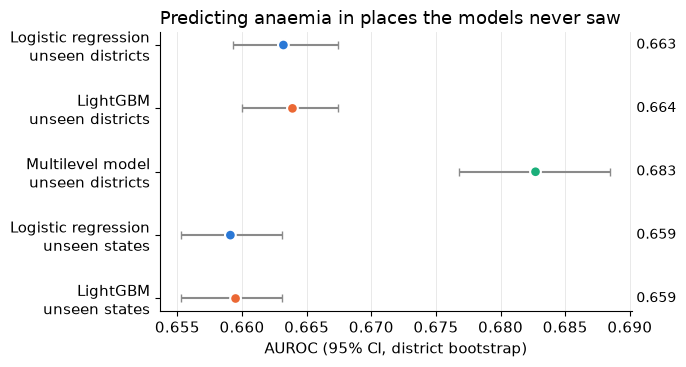

In [2]:
res = pd.read_csv(TABLES / "model_comparison.csv")
res = res[res["experiment"] != "A: unseen districts, all children"].reset_index(drop=True)
labels = [f"{NAMES[m]}\n{e.split(',')[0][3:]}" for e, m in zip(res["experiment"], res["model"])]

fig, ax = plt.subplots(figsize=(7, 3.8))
y = np.arange(len(res))[::-1]
ax.errorbar(res["auroc"], y,
            xerr=[res["auroc"] - res["auroc_ci_low"], res["auroc_ci_high"] - res["auroc"]],
            fmt="none", ecolor="#8a8a8a", elinewidth=1.5, capsize=3)
ax.scatter(res["auroc"], y, c=[COLORS[m] for m in res["model"]], s=60, zorder=3,
           edgecolors="white", linewidths=1.5)
for xi, yi in zip(res["auroc"], y):
    ax.text(res["auroc_ci_high"].max() + 0.002, yi, f"{xi:.3f}", va="center", fontsize=10)
ax.set_yticks(y, labels)
ax.set_xlabel("AUROC (95% CI, district bootstrap)")
ax.set_title("Predicting anaemia in places the models never saw", loc="left")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIGURES / "model_comparison.png", dpi=200)
plt.show()

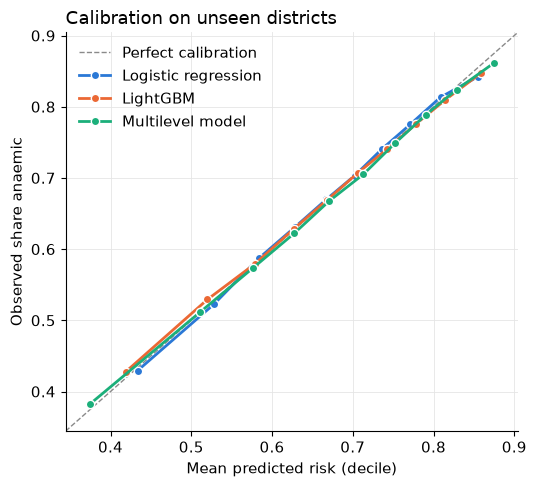

In [3]:
cal = pd.read_csv(TABLES / "calibration_unseen_districts.csv")
fig, ax = plt.subplots(figsize=(5.5, 5))
lims = [cal[["predicted", "observed"]].min().min() - 0.03,
        cal[["predicted", "observed"]].max().max() + 0.03]
ax.plot(lims, lims, color="#8a8a8a", linewidth=1, linestyle="--", label="Perfect calibration")
for model, d in cal.groupby("model", sort=False):
    ax.plot(d["predicted"], d["observed"], color=COLORS[model], linewidth=2,
            marker="o", markersize=6, markeredgecolor="white", label=NAMES[model])
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Mean predicted risk (decile)")
ax.set_ylabel("Observed share anaemic")
ax.set_title("Calibration on unseen districts", loc="left")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES / "calibration_unseen_districts.png", dpi=200)
plt.show()

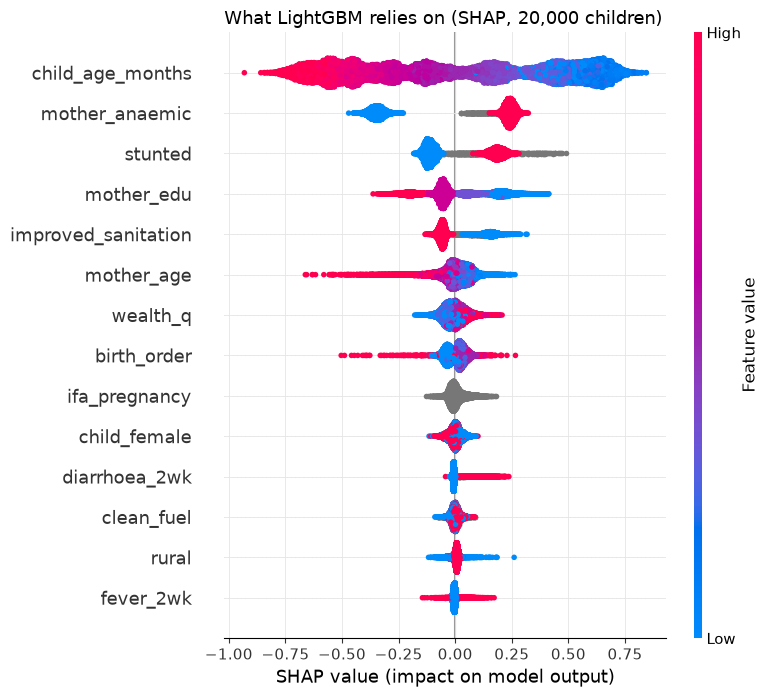

In [4]:
df = pd.read_parquet(ROOT / "data" / "processed" / "analysis.parquet")
features = ["child_age_months", "child_female", "birth_order", "stunted",
            "diarrhoea_2wk", "fever_2wk", "mother_age", "mother_edu",
            "mother_anaemic", "wealth_q", "rural", "clean_fuel",
            "improved_sanitation", "ifa_pregnancy"]
X = df[features].astype({"ifa_pregnancy": "category"})
gbm = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31,
                         min_child_samples=200, subsample=0.8, subsample_freq=1,
                         colsample_bytree=0.8, random_state=42, verbose=-1)
gbm.fit(X, df["anaemic"])

sample = X.sample(20_000, random_state=42) if len(X) > 20_000 else X
values = shap.TreeExplainer(gbm)(sample)
shap.plots.beeswarm(values, max_display=14, show=False)
plt.title("What LightGBM relies on (SHAP, 20,000 children)", loc="left")
plt.tight_layout()
plt.savefig(FIGURES / "shap_beeswarm.png", dpi=200)
plt.show()

In [5]:
numeric = sample.drop(columns="ifa_pregnancy").astype(float)
shap_vals = pd.DataFrame(values.values, columns=features, index=sample.index)
ranking = pd.DataFrame({
    "mean_abs_shap": shap_vals.abs().mean(),
    # + means higher feature values push predicted risk up.
    "direction": [np.sign(np.corrcoef(numeric[f].fillna(numeric[f].median()),
                                      shap_vals[f])[0, 1]) if f in numeric else np.nan
                  for f in features],
}).sort_values("mean_abs_shap", ascending=False)
ranking["rank"] = range(1, len(ranking) + 1)
ranking.round(4).to_csv(TABLES / "shap_ranking.csv")
ranking.round(4)

,mean_abs_shap,direction,rank
child_age_months,0.4083,-1.0,1
mother_anaemic,0.2833,1.0,2
stunted,0.1402,1.0,3
mother_edu,0.1111,-1.0,4
improved_sanitation,0.0849,-1.0,5
mother_age,0.0550,-1.0,6
wealth_q,0.0361,1.0,7
birth_order,0.0332,1.0,8
ifa_pregnancy,0.0217,NaN,9
child_female,0.0203,-1.0,10


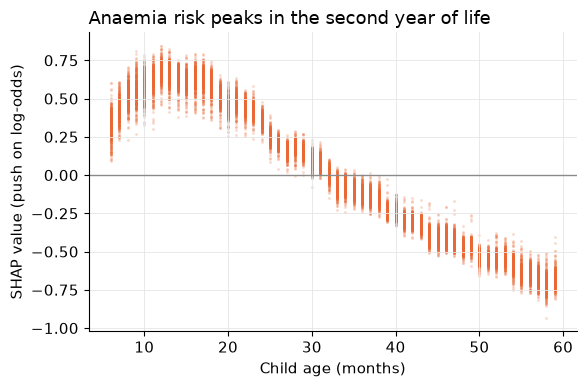

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(sample["child_age_months"], shap_vals["child_age_months"], s=4,
           alpha=0.25, color=COLORS["lightgbm"], linewidths=0)
ax.axhline(0, color="#8a8a8a", linewidth=1)
ax.set_xlabel("Child age (months)")
ax.set_ylabel("SHAP value (push on log-odds)")
ax.set_title("Anaemia risk peaks in the second year of life", loc="left")
fig.tight_layout()
fig.savefig(FIGURES / "shap_age_dependence.png", dpi=200)
plt.show()